In [108]:
from pathlib import Path
import os 
import numpy as np
import tensorflow as tf 
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

folder_data = Path('../Data')

def check_ext_corr (data_folder):
    VALID_EXTENSIONS = {'.jpg', '.png', '.jpeg', '.bmp'}
    corrupted_files = []
    invalid_ext_files = []
    for file in data_folder.rglob('*'):
        if file.is_file():
            if file.suffix.lower() not in VALID_EXTENSIONS:
                invalid_ext_files.append(file)
                
            if file.stat().st_size == 0:
                corrupted_files.append(file)
    print(f"Total invalid extensions: {len(invalid_ext_files)}")
    for f in invalid_ext_files:
        print(f" -> Invalid: {f}")

    print(f"\nTotal corrupted/empty files: {len(corrupted_files)}")
    for f in corrupted_files:
        print(f" -> Corrupted: {f}")
    remove_badFiles(corrupted_files+invalid_ext_files)

def remove_badFiles(bad_files):
    for bad_file in bad_files :
        os.remove(bad_file)




In [109]:
import cv2


def check_img(data_folder):
    failed_files = []

    for file in data_folder.rglob('*'):
        if file.is_file():
            try:
                image = cv2.imread(file)
                if image is None:
                    failed_files.append(file)
                    raise FileNotFoundError(f'image dosn\'t exist {file}')
            except FileNotFoundError as e:
                print(f'Error :',e)
            except Exception as e :
                print(f'P-Error :',e)
    remove_badFiles(failed_files)



In [110]:
classes = os.listdir('../Data')
print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [111]:
def img_melange(folder_data):
    images = []
    labels = []
    for file in folder_data.rglob('*'):
        if file.is_file():
            images.append(cv2.imread(str(file)))
            labels.append(file.parts[2])
    print(f"Total images : {len(images)}")
    print(f"Total labels : {len(labels)}")
    return images , labels


In [112]:
output_path = Path('../Resized_data')
output_path.mkdir(parents=True , exist_ok=True)
TARGET_SIZE = (224,224)
for file in folder_data.rglob('*'):
    if file.is_file() :
        try:
                img = cv2.imread(file)
                resized = cv2.resize(img , TARGET_SIZE , interpolation=cv2.INTER_AREA)
                save_path = output_path / file.relative_to(folder_data)
                save_path.parent.mkdir(parents=True , exist_ok=True)
                cv2.imwrite(save_path , resized)
        except Exception as e:
            print('Error :' , e)




In [113]:
resized_data_folder = Path('../Resized_data')
images , labels = img_melange(resized_data_folder)
print(images[::10])
print(labels[::10])

Total images : 7023
Total labels : 7023
[array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(224, 224, 3), dtype=uint8), array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [

In [114]:
images = np.array(images)
labels = np.array(labels)

In [115]:
images.shape

(7023, 224, 224, 3)

In [116]:
unique_classes , count = np.unique(labels , return_counts=True)

print(unique_classes , count)

['glioma' 'meningioma' 'notumor' 'pituitary'] [1621 1645 2000 1757]


<BarContainer object of 4 artists>

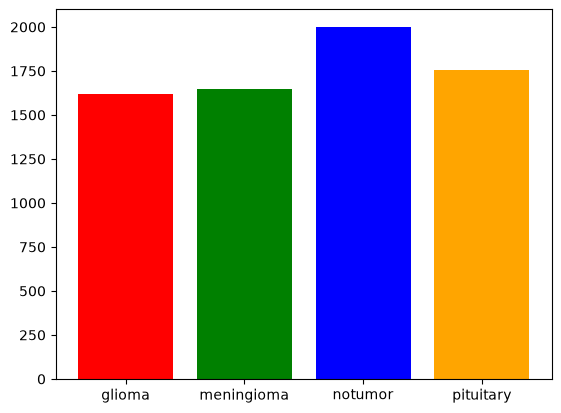

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.bar(unique_classes , count , color=["red",
                                        "green", "blue" , 'orange'])



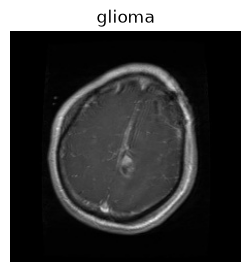

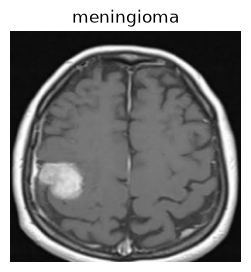

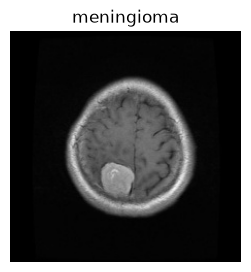

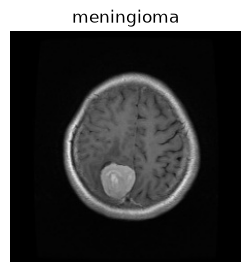

In [118]:
for i in count :
    img = cv2.cvtColor(images[i-1] , cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(3,3))
    plt.title(labels[i-1])
    plt.imshow(img)
    plt.axis('off')
    plt.show()

In [119]:
X_train,X_test , y_train , y_test = train_test_split(
    images , 
    labels ,
    test_size=0.15,
    random_state=42,
    shuffle=True,
    stratify=labels
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")


X_train shape: (5969, 224, 224, 3), y_train shape: (5969,)
X_test shape:  (1054, 224, 224, 3),  y_test shape:  (1054,)


In [120]:
encoder = LabelEncoder()

y_train_encoded = encoder.fit_transform(y_train)
y_test_encoded = encoder.transform(y_test) 

In [121]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name='data_augmentation')

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(224 , 224 , 3)),
    
    data_augmentation,
    
    tf.keras.layers.Rescaling(1./255),
    
    tf.keras.layers.Conv2D(32 , (3 , 3) , activation='relu' , padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    
    tf.keras.layers.Conv2D(64 , (3 , 3) , activation='relu' , padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    
    tf.keras.layers.Conv2D(128 , (3 , 3) , activation='relu' , padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    
    tf.keras.layers.Conv2D(256 , (3 , 3) , activation='relu' , padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    
    tf.keras.layers.Conv2D(512 , (3 , 3) , activation='relu' , padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2,2)),
    
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128 , activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4 , activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()



Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 14, 14, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 14, 14, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,784,452 (18.25 MB)

 Trainable params: 4,782,468 (18.24 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [122]:
callbacks = [
    # tf.keras.callbacks.EarlyStopping(monitor='val_loss' , patience=5 , restore_best_weights=True),
    
    tf.keras.callbacks.ModelCheckpoint('best_brain_tumor_model.keras' , monitor='val_loss' , save_best_only=True)
]

In [125]:
history = model.fit(
    X_train ,
    y_train_encoded , 
    epochs=30,
    batch_size =32,
    validation_split=0.15,
    callbacks=callbacks,
    shuffle=True
)


Epoch 1/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - accuracy: 0.9162 - loss: 0.2510 - val_accuracy: 0.8594 - val_loss: 0.6374
Epoch 2/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 23s 142ms/step - accuracy: 0.9217 - loss: 0.2386 - val_accuracy: 0.5926 - val_loss: 3.6089
Epoch 3/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 54s 343ms/step - accuracy: 0.9208 - loss: 0.2254 - val_accuracy: 0.9263 - val_loss: 0.2777
Epoch 4/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 56s 353ms/step - accuracy: 0.9208 - loss: 0.2443 - val_accuracy: 0.9408 - val_loss: 0.2331
Epoch 5/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 22s 137ms/step - accuracy: 0.9296 - loss: 0.2228 - val_accuracy: 0.9297 - val_loss: 0.2333
Epoch 6/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 22s 137ms/step - accuracy: 0.9363 - loss: 0.1878 - val_accuracy: 0.9509 - val_loss: 0.1594
Epoch 7/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 22s 136ms/step - accuracy: 0.9290 - loss: 0.2179 - val_accuracy: 0.8583 - val_loss: 0.5348
Epoch 8/30
159/159 ━━━━━━━━━━━━━━━━━━━━ 22s 136ms/step - accuracy: 0.9314 - loss: 0

In [126]:
test_loss, test_acc = model.evaluate(X_test, y_test_encoded)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9336 - loss: 0.2398
Test Accuracy: 93.36%
Test Loss: 0.2398


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step
              precision    recall  f1-score   support

      glioma       1.00      0.84      0.91       243
  meningioma       0.88      0.91      0.89       247
     notumor       0.98      0.98      0.98       300
   pituitary       0.89      0.99      0.94       264

    accuracy                           0.93      1054
   macro avg       0.94      0.93      0.93      1054
weighted avg       0.94      0.93      0.93      1054



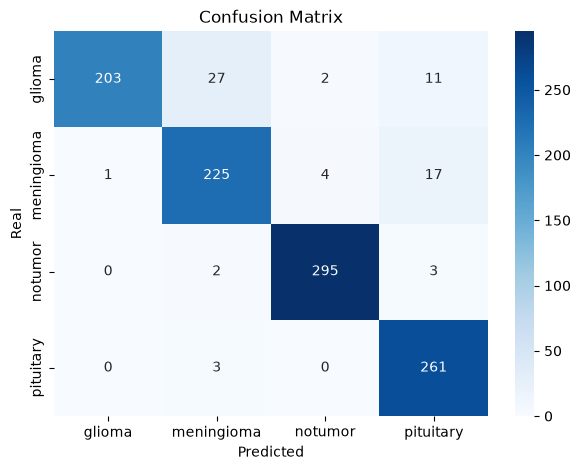

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

class_names = list(encoder.classes_)
print(classification_report(y_test_encoded, y_pred, target_names=class_names))

cm = confusion_matrix(y_test_encoded, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('Confusion Matrix')
plt.show()